In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

<h1>Build-in NumPy and SciPy functions</h1>

In NumPy: diff(y) = y[1:] - y[0:-1]


Have a list of data points, better use NumPy function to evaluate since it returns the list of data.

SciPy works directly with a Python function. Note: `scipy.misc.derivative` was removed in SciPy 1.12, so the cell below implements the same central-difference formula explicitly.

In [2]:
from scipy import optimize 

f = lambda x: - x*(20-2*x)**2


result = optimize.minimize(f, 0)
print(result)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -592.5925925925925
        x: [ 3.333e+00]
      nit: 7
      jac: [-7.629e-06]
 hess_inv: [[ 1.250e-02]]
     nfev: 16
     njev: 8


<h1>3.70</h1>

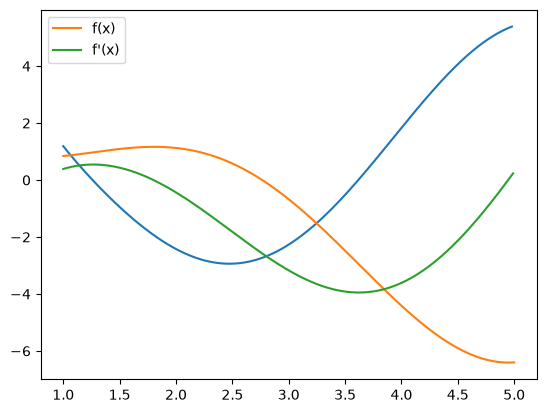

In [3]:
f = lambda x: x*np.sin(x) - np.log(x)
x = np.linspace(1, 5, 400)
dx = x[1] - x[0]
y = f(x)
df = np.diff(y)/dx
d2f = np.diff(df)/dx

df2 = np.diff(y, 2)/dx**2

plt.plot(x[:-2], df2)

x_df = x[:-1]
x_d2f = x_df[:-1]

# Plot f(x), f'(x), and f''(x)
plt.plot(x, y, label='f(x)')
plt.plot(x_df, df, label="f'(x)")
#plt.plot(x_d2f, d2f, label="f''(x) Approximation")
plt.legend()
plt.show()


<h1>3.72</h1>

Differentiating with smaller and smaller dx values is a strategy of trade-off. A small dx can lead to a more accurate approximation of the derivative we want, but it can also lead to numerical errors since we have issues of machine precision of floating point numbers.

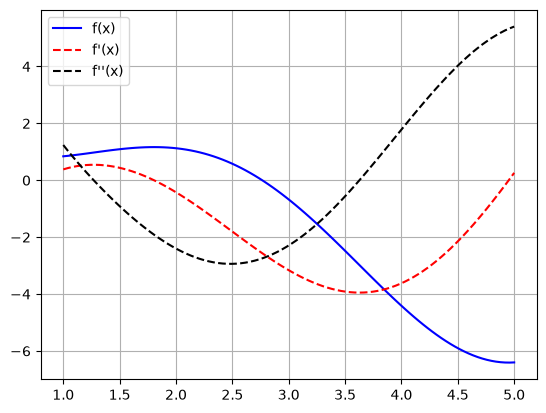

In [4]:
# scipy.misc.derivative was removed in SciPy 1.12. This helper applies the
# same central-difference stencils without an extra dependency.
def derivative(f, x, dx=1e-6, n=1):
    if n == 1:
        return (f(x + dx) - f(x - dx)) / (2 * dx)
    if n == 2:
        return (f(x + dx) - 2 * f(x) + f(x - dx)) / dx**2
    raise ValueError("only n=1 and n=2 are supported")


f = lambda x: np.sin(x)*x-np.log(x)
x = np.linspace(1,5,100) # x domain: 100 points between 1 and 5
df = derivative(f,x,dx=1e-6)
df2 = derivative(f,x,dx=1e-6,n=2)
plt.plot(x,f(x),'b',x,df,'r--',x,df2,'k--')
plt.legend(["f(x)","f'(x)","f''(x)"])
plt.grid()
plt.show()

<h1>3.76</h1>

It is asking to find the total amount of water, what firstly jump into my mind is the Trapezoidal Rule or Simpson's Rule. They are suitable to solve the problem when we have given data points with specifically spaced and the rate changes probably linearly over time.

<h1>3.79</h1>

In [5]:
f = lambda x: - x*(20-2*x)**2


result = sp.optimize.minimize(f, 1)
print(result)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -592.5925925925924
        x: [ 3.333e+00]
      nit: 6
      jac: [-7.629e-06]
 hess_inv: [[ 1.250e-02]]
     nfev: 14
     njev: 7


In [6]:
optimal_x, optimal_volume = result.x, -result.fun

print(f"x value is {optimal_x} and the optimal volume is {optimal_volume}")

x value is [3.33333326] and the optimal volume is 592.5925925925924
